In [1]:
!pip install -q kagglehub

In [6]:
import kagglehub
import os


In [7]:
path = kagglehub.dataset_download("crawford/emnist")

print("Dataset Downloaded Successfully!")

print("Dataset Path:", path)
for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

100%|██████████| 1.24G/1.24G [00:32<00:00, 40.4MB/s]

Extracting files...


Dataset Downloaded Successfully!
Dataset Path: /root/.cache/kagglehub/datasets/crawford/emnist/versions/3
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-balanced-test.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-digits-test.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-byclass-mapping.txt
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-bymerge-test.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-byclass-train.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-digits-mapping.txt
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-mnist-mapping.txt
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-mnist-train.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-bymerge-train.csv
/root/.cache/kagglehub/datasets/crawford/emnist/versions/3/emnist-balanced-mapping.txt
/root/.cache/kagglehub/datasets/crawford/emnist/versi

In [8]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")



In [9]:
import kagglehub

# Reuse downloaded dataset path
if "path" not in globals() or not os.path.exists(path):
    path = kagglehub.dataset_download("crawford/emnist")

train_path = os.path.join(
    path, "emnist-balanced-train.csv"
)

test_path = os.path.join(
    path, "emnist-balanced-test.csv"
)

mapping_path = os.path.join(
    path, "emnist-balanced-mapping.txt"
)

print("Training File Exists:", os.path.exists(train_path))
print("Testing File Exists:", os.path.exists(test_path))
print("Mapping File Exists:", os.path.exists(mapping_path))

Training File Exists: True
Testing File Exists: True
Mapping File Exists: True


In [10]:
train_df = pd.read_csv(
    train_path,
    header=None,
    dtype=np.uint8
)

test_df = pd.read_csv(
    test_path,
    header=None,
    dtype=np.uint8
)

print("Training Shape:", train_df.shape)
print("Testing Shape:", test_df.shape)

display(train_df.head())

Training Shape: (112800, 785)
Testing Shape: (18800, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,45,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,36,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,43,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,15,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [11]:
print("Training Samples:", len(train_df))
print("Testing Samples:", len(test_df))

print("Total Features:", train_df.shape[1] - 1)

print("Number of Classes:",
      train_df.iloc[:, 0].nunique())

print("Missing Values:", train_df.isnull().sum().sum())

Training Samples: 112800
Testing Samples: 18800
Total Features: 784
Number of Classes: 47
Missing Values: 0


In [12]:
mapping = np.loadtxt(
    mapping_path,
    dtype=int
)

class_names = [
    chr(int(character_code))
    for character_code in mapping[:, 1]
]

print("Total Classes:", len(class_names))
print("Characters:", class_names)

Total Classes: 47
Characters: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'd', 'e', 'f', 'g', 'h', 'n', 'q', 'r', 't']


In [13]:
# Training data
X = train_df.iloc[:, 1:].to_numpy()
y = train_df.iloc[:, 0].to_numpy(dtype=np.int64)

# Testing data
X_test = test_df.iloc[:, 1:].to_numpy()
y_test = test_df.iloc[:, 0].to_numpy(dtype=np.int64)

print("X Shape:", X.shape)
print("y Shape:", y.shape)

print("X Test Shape:", X_test.shape)
print("y Test Shape:", y_test.shape)

X Shape: (112800, 784)
y Shape: (112800,)
X Test Shape: (18800, 784)
y Test Shape: (18800,)


In [14]:
X = X.reshape(-1, 28, 28)
X_test = X_test.reshape(-1, 28, 28)

print("Training Image Shape:", X.shape)
print("Testing Image Shape:", X_test.shape)

Training Image Shape: (112800, 28, 28)
Testing Image Shape: (18800, 28, 28)


In [15]:
X = np.transpose(X, (0, 2, 1))
X_test = np.transpose(X_test, (0, 2, 1))

print("Orientation Corrected!")

Orientation Corrected!


In [16]:
X = X.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension
X = np.expand_dims(X, axis=-1)
X_test = np.expand_dims(X_test, axis=-1)

print("Training Shape:", X.shape)
print("Testing Shape:", X_test.shape)

print("Minimum Pixel:", X.min())
print("Maximum Pixel:", X.max())

Training Shape: (112800, 28, 28, 1)
Testing Shape: (18800, 28, 28, 1)
Minimum Pixel: 0.0
Maximum Pixel: 1.0


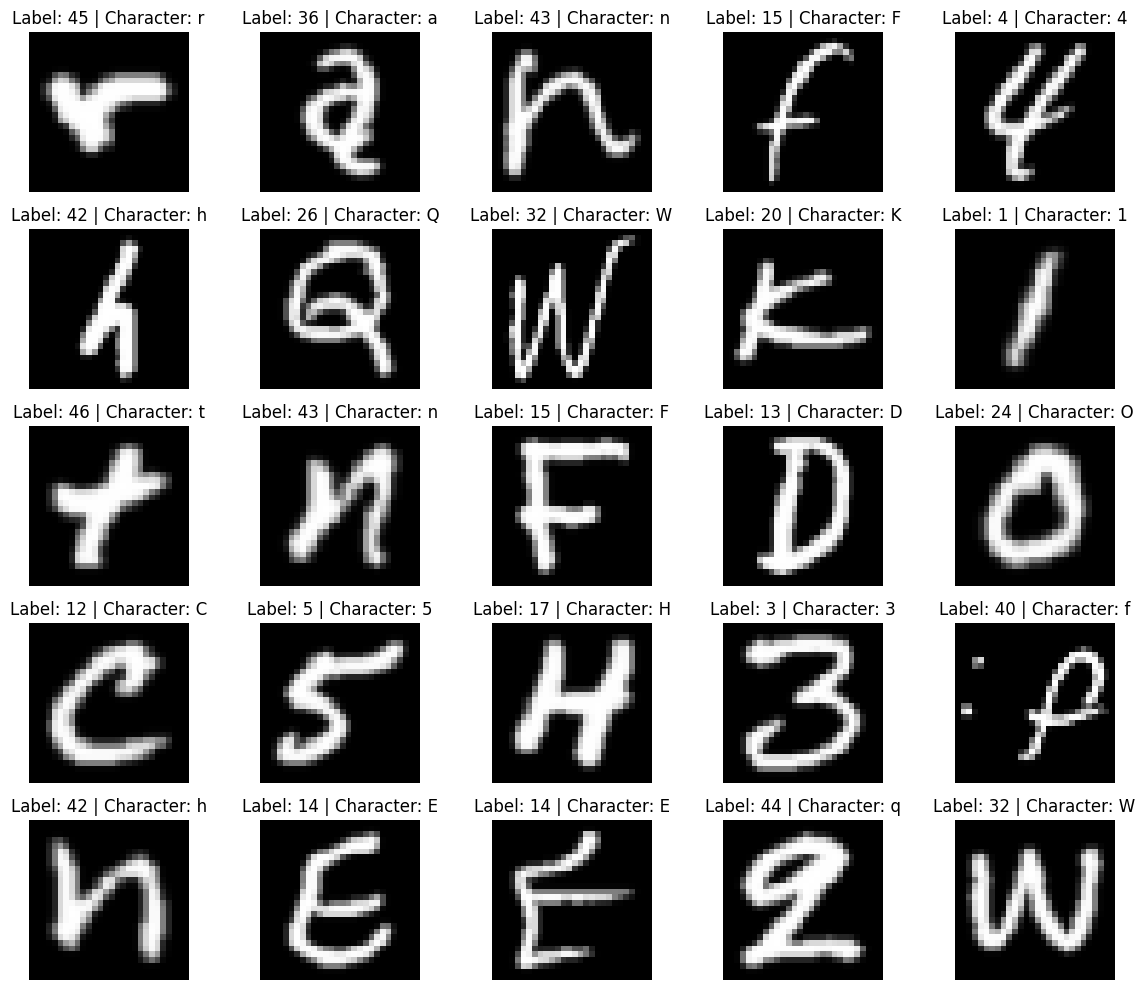

In [17]:
plt.figure(figsize=(12, 10))

for i in range(25):

    plt.subplot(5, 5, i + 1)

    plt.imshow(X[i].squeeze(), cmap="gray")

    label = y[i]

    plt.title(
        f"Label: {label} | Character: {class_names[label]}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [18]:
indices = np.arange(len(y))

train_idx, val_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=42,
    stratify=y
)

X_train = X[train_idx]
y_train = y[train_idx]

X_val = X[val_idx]
y_val = y[val_idx]

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Training Data: (95880, 28, 28, 1)
Validation Data: (16920, 28, 28, 1)
Testing Data: (18800, 28, 28, 1)


In [19]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(28, 28, 1)),

    # First Convolution Block
    tf.keras.layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    tf.keras.layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    tf.keras.layers.Conv2D(
        128, (3, 3),
        activation="relu",
        padding="same"
    ),

    # Flatten
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(
        128,
        activation="relu"
    ),

    tf.keras.layers.Dropout(0.4),

    # Output Layer
    tf.keras.layers.Dense(
        47,
        activation="softmax"
    )

])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       802,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 47)             │         6,063 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 901,679 (3.44 MB)

 Trainable params: 901,679 (3.44 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

print("CNN Model Compiled Successfully!")

CNN Model Compiled Successfully!


In [21]:
callbacks = [

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )

]

In [22]:
history = model.fit(

    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=15,

    batch_size=128,

    callbacks=callbacks,

    verbose=1

)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 200s 260ms/step - accuracy: 0.7069 - loss: 0.9834 - val_accuracy: 0.8449 - val_loss: 0.4521 - learning_rate: 0.0010
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 177s 235ms/step - accuracy: 0.8332 - loss: 0.5023 - val_accuracy: 0.8663 - val_loss: 0.3734 - learning_rate: 0.0010
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 161s 215ms/step - accuracy: 0.8537 - loss: 0.4290 - val_accuracy: 0.8734 - val_loss: 0.3563 - learning_rate: 0.0010
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 206s 220ms/step - accuracy: 0.8649 - loss: 0.3858 - val_accuracy: 0.8780 - val_loss: 0.3368 - learning_rate: 0.0010
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 166s 221ms/step - accuracy: 0.8740 - loss: 0.3520 - val_accuracy: 0.8787 - val_loss: 0.3386 - learning_rate: 0.0010
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 161s 215ms/step - accuracy: 0.8785 - loss: 0.3322 - val_accuracy: 0.8832 - val_loss: 0.3308 - learning_rate: 0.0010
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 157s 209ms/step - accura

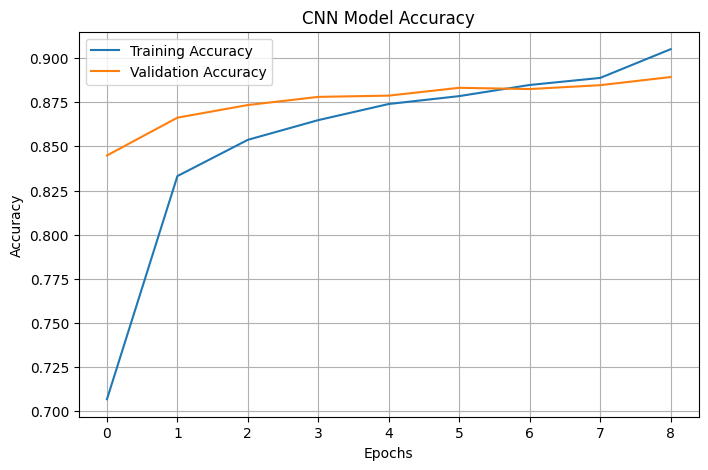

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

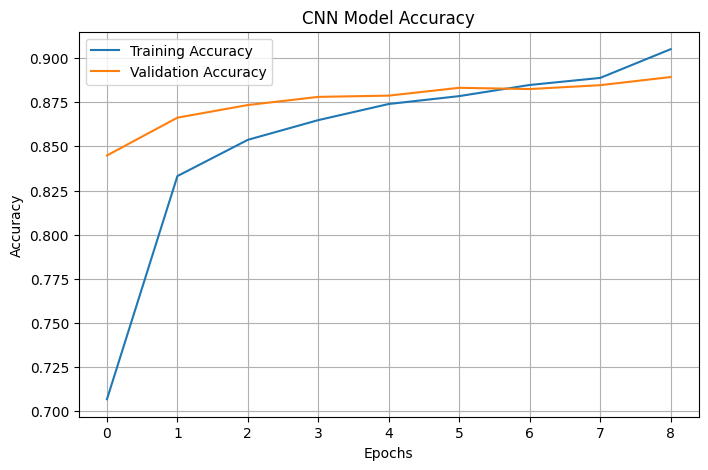

In [24]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.show()

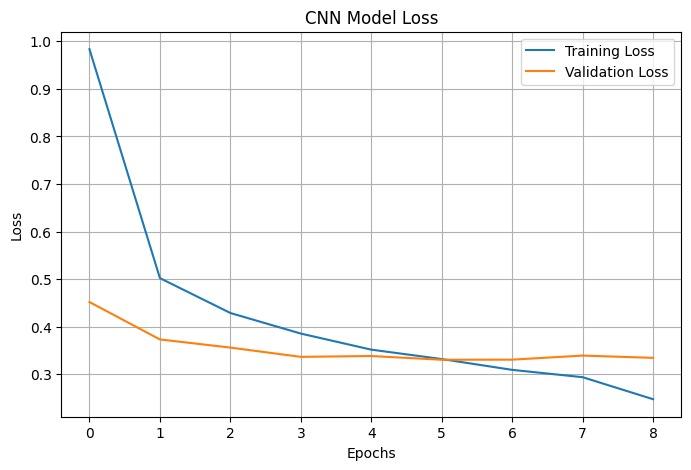

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

In [26]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

588/588 ━━━━━━━━━━━━━━━━━━━━ 10s 17ms/step - accuracy: 0.8800 - loss: 0.3436
Test Loss: 0.3435910642147064
Test Accuracy: 87.99999952316284 %


In [27]:
y_prob = model.predict(
    X_test,
    batch_size=256,
    verbose=1
)

y_pred = np.argmax(y_prob, axis=1)

print("Predictions Generated!")
print("Total Predictions:", len(y_pred))

74/74 ━━━━━━━━━━━━━━━━━━━━ 9s 116ms/step
Predictions Generated!
Total Predictions: 18800


In [28]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="macro",
    zero_division=0
)

results_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision (Macro)",
        "Recall (Macro)",
        "F1 Score (Macro)"
    ],

    "Score": [
        accuracy,
        precision,
        recall,
        f1
    ]
})

display(results_df)

,Metric,Score
0,Accuracy,0.880000
1,Precision (Macro),0.884351
2,Recall (Macro),0.880000
3,F1 Score (Macro),0.877693


In [29]:
print(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(47),
        target_names=class_names,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.63      0.80      0.71       400
           1       0.54      0.68      0.60       400
           2       0.90      0.90      0.90       400
           3       0.99      0.97      0.98       400
           4       0.94      0.92      0.93       400
           5       0.95      0.88      0.91       400
           6       0.91      0.95      0.93       400
           7       0.97      0.98      0.98       400
           8       0.92      0.93      0.92       400
           9       0.63      0.90      0.74       400
           A       0.98      0.96      0.97       400
           B       0.97      0.96      0.97       400
           C       0.94      0.96      0.95       400
           D       0.93      0.92      0.92       400
           E       0.99      0.98      0.98       400
           F       0.73      0.49      0.59       400
           G       0.92      0.96      0.94       400
           H       0.94    

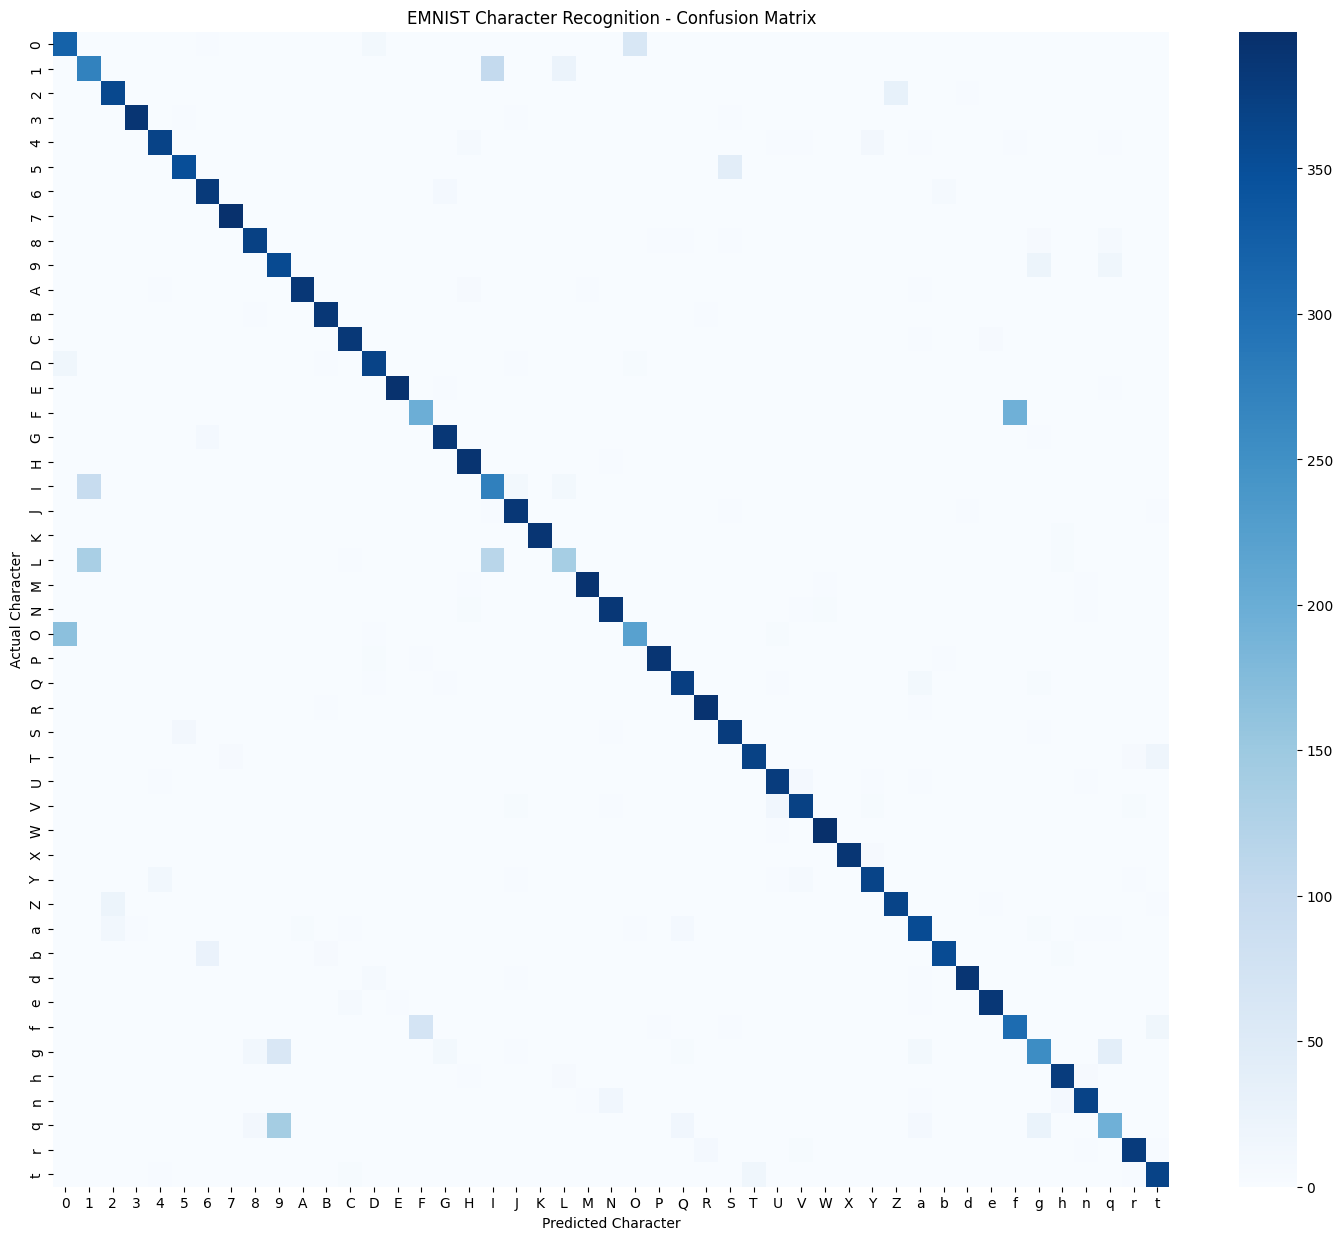

In [30]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(47)
)

plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("EMNIST Character Recognition - Confusion Matrix")
plt.xlabel("Predicted Character")
plt.ylabel("Actual Character")

plt.show()

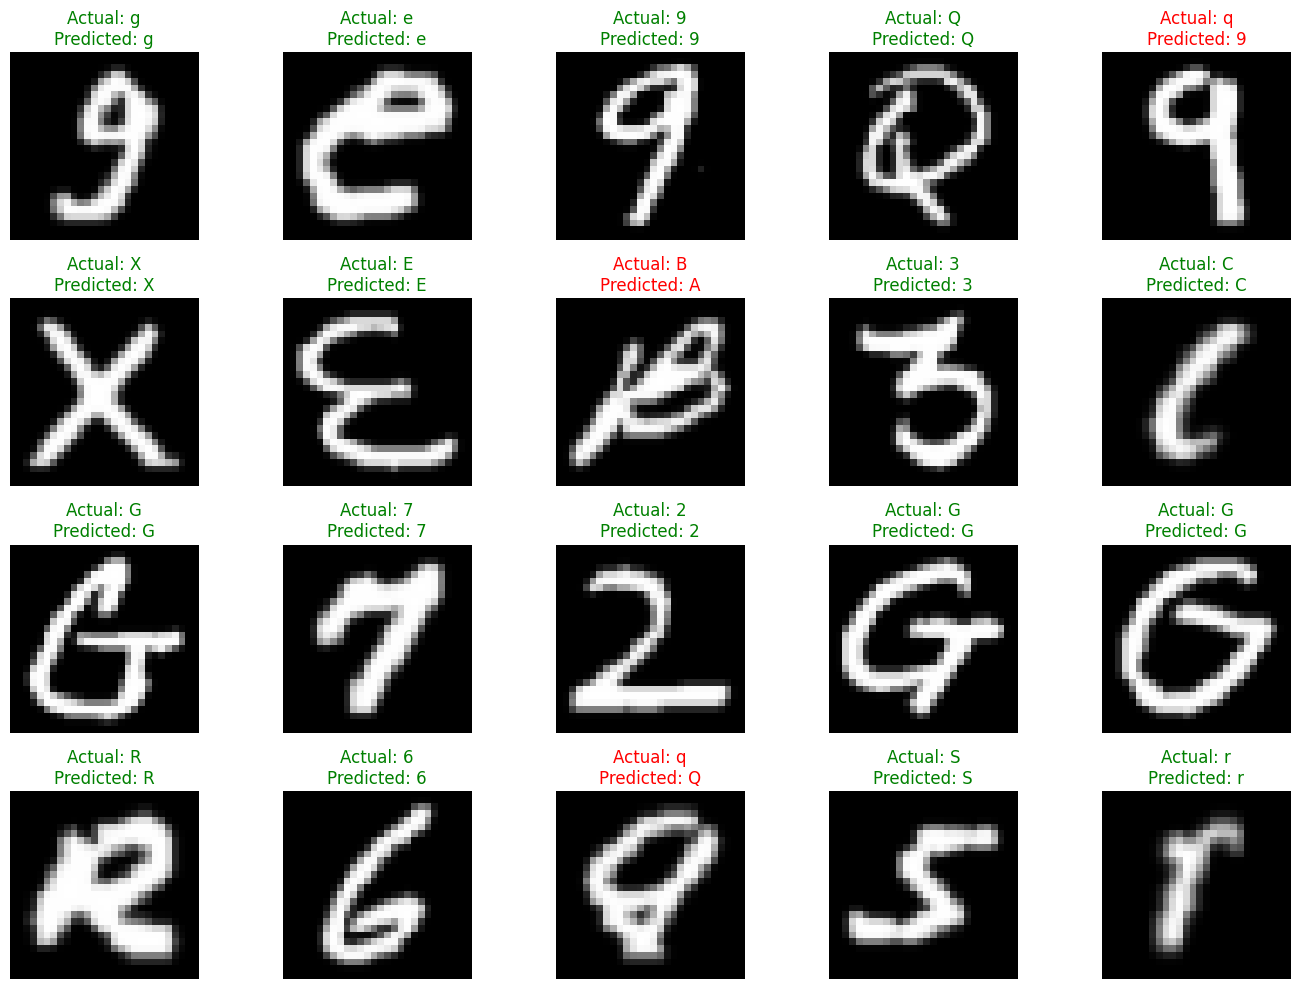

In [31]:
plt.figure(figsize=(14, 10))

for i in range(20):

    plt.subplot(4, 5, i + 1)

    plt.imshow(
        X_test[i].squeeze(),
        cmap="gray"
    )

    actual = class_names[y_test[i]]
    predicted = class_names[y_pred[i]]

    color = "green" if y_test[i] == y_pred[i] else "red"

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [32]:
def predict_character(index):

    image = X_test[index]

    prediction = model.predict(
        image[np.newaxis, ...],
        verbose=0
    )

    predicted_label = np.argmax(prediction[0])

    character = class_names[predicted_label]

    confidence = np.max(prediction[0]) * 100

    plt.imshow(image.squeeze(), cmap="gray")
    plt.axis("off")

    plt.title(
        f"Prediction: {character} | Confidence: {confidence:.2f}%"
    )

    plt.show()

    print("Predicted Character:", character)
    print("Actual Character:", class_names[y_test[index]])
    print("Confidence:", round(confidence, 2), "%")

In [33]:
save_dir = "/content/drive/MyDrive/Task 3"

os.makedirs(save_dir, exist_ok=True)

model.save(
    os.path.join(save_dir, "emnist_cnn_model.keras")
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [34]:
results_df.to_csv(
    os.path.join(save_dir, "model_evaluation.csv"),
    index=False
)

with open(
    os.path.join(save_dir, "class_mapping.json"),
    "w"
) as f:

    json.dump(class_names, f)

print("Evaluation Results Saved!")
print("Class Mapping Saved!")

Evaluation Results Saved!
Class Mapping Saved!
